In [8]:
from pathlib import Path
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from torus_clock.data import load_rte

In [9]:
load = load_rte(*sorted(Path("../data/raw/rte").glob("*.xls")))
fr = holidays.France(years=range(2023, 2027))
hol = pd.Series(fr).sort_index()
hol = hol[(hol.index >= load.index[0].date()) & (hol.index <= load.index[-1].date())]
hol = pd.DataFrame({"name": hol, "weekday": pd.to_datetime(hol.index).day_name()})
hol

,name,weekday
2023-01-01,Jour de l'an,Sunday
2023-04-10,Lundi de Pâques,Monday
2023-05-01,Fête du Travail,Monday
2023-05-08,Fête de la Victoire,Monday
2023-05-18,Ascension,Thursday
2023-05-29,Lundi de Pentecôte,Monday
2023-07-14,Fête nationale,Friday
2023-08-15,Assomption,Tuesday
2023-11-01,Toussaint,Wednesday
2023-11-11,Armistice,Saturday


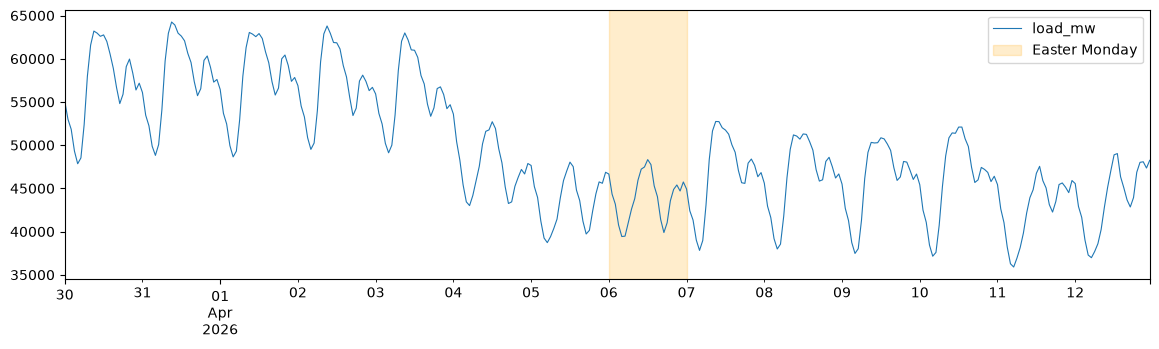

In [10]:
local = load.tz_convert("Europe/Paris")
week = local["2026-03-30":"2026-04-12"]
ax = week.plot(figsize=(14, 3.5), lw=0.8)
ax.axvspan("2026-04-06", "2026-04-07", color="orange", alpha=0.2, label="Easter Monday")
ax.legend()
plt.show()

In [11]:
import torch
from torus_clock.data import make_windows, calendar_phases
from torus_clock.model import load_model, capture
from torus_clock.probes import fit_probe
from torus_clock.steering import day_of

T, H, L = 512, 64, "layer 6"
model = load_model()
patch_end = 16 * np.arange(32) + 15
hol_dates = set(hol.index)

# weekly probe, trained on ordinary (non-holiday) tokens from Jan-Aug 2025
x_tr, idx_tr, d_tr, w_tr = make_windows(load, "2025-01-01", "2025-09-01")
A_tr = capture(model, torch.tensor(x_tr[:, :T]))[0][L][:, :32].cpu().numpy()
tok_local = pd.DatetimeIndex(idx_tr[:, patch_end].ravel()).tz_convert("Europe/Paris")
keep = ~pd.Index(tok_local.date).isin(hol_dates).reshape(-1, 32)        # True for ordinary tokens
probe = fit_probe(A_tr[keep], w_tr[:, patch_end][keep])


def window_ending(end_local):
    """One window whose context ends at end_local (local time): x [T+H], token times [32]."""
    i = load.index.get_loc(pd.Timestamp(end_local, tz="Europe/Paris").tz_convert("UTC")) + 1
    return load.values[i - T:i + H].astype(np.float32), load.index[i - T:i][patch_end]


# one window per weekday holiday, ending at 23:00 on the day after it
weekday_hols = hol[~hol.weekday.isin(["Saturday", "Sunday"])]
rows = []
for date, r in weekday_hols.iterrows():
    x, ttimes = window_ending(f"{date + pd.Timedelta(days=1)} 23:00")
    A = capture(model, torch.tensor(x[None, :T]))[0][L][0, :32].cpu().numpy()
    pred = probe(A)
    dec_day = day_of(np.mod(np.arctan2(pred[:, 1], pred[:, 0]), 2 * np.pi))
    loc = ttimes.tz_convert("Europe/Paris")
    for tt, dd in zip(loc, dec_day):
        rel = (tt.date() - date).days                       # -1 day before, 0 holiday, +1 day after
        if -2 <= rel <= 1:
            rows.append({"holiday": r["name"], "date": date, "rel_day": rel,
                         "true": tt.day_name()[:3], "decoded": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][dd]})

dec = pd.DataFrame(rows)
pd.crosstab([dec.rel_day, dec.true], dec.decoded)

Loading weights: 100%|██████████| 143/143 [00:00<00:00, 6329.52it/s]


KeyboardInterrupt: 

In [ ]:
def run_window(end_local):
    """Forecast error (scale-free MAE) and the decoded day of the last token, for one window."""
    x, ttimes = window_ending(end_local)
    acts, out = capture(model, torch.tensor(x[None, :T]))
    pred = out.quantile_preds[0, 4].numpy()
    err = np.nanmean(np.abs(pred - x[T:])) / np.nanstd(x[:T])
    p = probe(acts[L][0, :32].cpu().numpy())[-1]                         # last patch token
    decoded = day_of(np.mod(np.arctan2(p[1], p[0]), 2 * np.pi))
    return err, decoded


def near_holiday(day, before=7, after=3):
    return any(abs((day - h).days) <= max(before, after) and -before <= (day - h).days <= after for h in hol_dates)


rows = []
for date, r in weekday_hols.iterrows():
    try:
        err, decoded = run_window(f"{date} 23:00")
    except (KeyError, ValueError):                       # not enough history or future around this date
        continue
    controls = []
    for k in (-4, -3, -2, -1, 1, 2, 3, 4):
        d = date + pd.Timedelta(weeks=k)
        if not near_holiday(d):
            try:
                controls.append(run_window(f"{d} 23:00")[0])
            except (KeyError, ValueError):
                pass
    rows.append({"date": date, "holiday": r["name"], "weekday": r["weekday"][:3],
                 "misread": decoded != pd.Timestamp(date).dayofweek,
                 "decoded": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][decoded],
                 "err": err, "control err": np.mean(controls) if controls else np.nan})

res = pd.DataFrame(rows)
res["ratio"] = res["err"] / res["control err"]
res.round(3)

/tmp/ipykernel_33261/3177808075.py:31: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "misread": decoded != pd.Timestamp(date).dayofweek,
/tmp/ipykernel_33261/3177808075.py:31: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "misread": decoded != pd.Timestamp(date).dayofweek,
/tmp/ipykernel_33261/3177808075.py:31: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "misread": decoded != pd.Timestamp(date).dayofweek,
/tmp/ipykernel_33261/3177808075.py:31: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "misread": decoded != pd.Timestamp(date).dayofweek,
/tmp/ipykernel_33261/3177808075.py:31: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future ver

,date,holiday,weekday,misread,decoded,err,control err,ratio
0,2023-04-10,Lundi de Pâques,Mon,False,Mon,0.369,0.342,1.079
1,2023-05-01,Fête du Travail,Mon,True,Sun,0.171,0.330,0.517
2,2023-05-08,Fête de la Victoire,Mon,False,Mon,0.455,0.238,1.914
3,2023-05-18,Ascension,Thu,True,Fri,0.431,0.203,2.126
4,2023-05-29,Lundi de Pentecôte,Mon,False,Mon,0.268,0.103,2.605
5,2023-07-14,Fête nationale,Fri,True,Sat,0.170,0.128,1.319
6,2023-08-15,Assomption,Tue,True,Mon,0.431,0.155,2.772
7,2023-11-01,Toussaint,Wed,True,Tue,0.715,0.171,4.173
8,2023-12-25,Noël,Mon,False,Mon,0.328,0.278,1.182
9,2024-01-01,Jour de l'an,Mon,False,Mon,0.228,0.249,0.914


In [12]:
print(res.groupby("misread")["ratio"].agg(["median", "count"]).round(2))
print(res.groupby("weekday")["ratio"].agg(["median", "count"]).round(2))

         median  count
misread               
False      1.32     14
True       1.33     22
         median  count
weekday               
Fri        0.88      5
Mon        1.32     14
Thu        1.52      9
Tue        1.56      3
Wed        1.29      5


In [ ]:
def run_window_masked(end_local, mask_dates=()):
    """Like run_window, but with the given local dates set to NaN in the context. Returns the forecast bias and error."""
    x, _ = window_ending(end_local)
    times = load.index[load.index.get_loc(pd.Timestamp(end_local, tz="Europe/Paris").tz_convert("UTC")) + 1 - T:][:T]
    days = pd.Index(times.tz_convert("Europe/Paris").date)
    xc = x.copy()
    xc[:T][days.isin(list(mask_dates))] = np.nan
    pred = capture(model, torch.tensor(xc[None, :T]))[1].quantile_preds[0, 4].numpy()
    scale = np.nanstd(x[:T])
    return np.nanmean(pred - x[T:]) / scale, np.nanmean(np.abs(pred - x[T:])) / scale


out = []
for date in res["date"]:
    bias, err = run_window_masked(f"{date} 23:00")
    bias_m, err_m = run_window_masked(f"{date} 23:00", mask_dates=[date])
    out.append({"date": date, "bias": bias, "err masked": err_m})
fix = res.merge(pd.DataFrame(out), on="date")
fix["gain %"] = 100 * (1 - fix["err masked"] / fix["err"])
print(fix[["date", "holiday", "weekday", "ratio", "bias", "err", "err masked", "gain %"]].round(3))
print("median bias:", fix["bias"].median().round(3), "| median gain %:", fix["gain %"].median().round(1))

SyntaxError: invalid syntax (1533328105.py, line 17)